# PIPELINE JURNAL EKONOMI — VERSI ULANG & TERVERIFIKASI — Penelitian Ekonomi Pajak Daerah Jawa Timur (2014–2025)

**Usulan judul jurnal:** *Realisasi, Disparitas, dan Prediktabilitas Penerimaan Pajak Daerah di 38 Kabupaten/Kota Jawa Timur: Analisis Data Panel dan Peramalan Satu Tahun ke Depan, 2014–2025.*

**SUMBER TUNGGAL:** `pajak_daerah_jatim_2011_2026_v2.csv` (data pajak daerah tahunan dari DJPK yang disediakan peneliti). **Bukan** CSV APBD bulanan. Tahun **2011–2013 serta 2026 dikeluarkan**, dari analisis. Tahun 2026 merupakan tahun fiskal yang belum selesai ketika data diambil pada 4 November 2026.

### Pertanyaan penelitian yang dapat diuji
1. Bagaimana rasio realisasi terhadap anggaran, pertumbuhan nominal, dan konsentrasi penerimaan pajak daerah pada 2014–2025?
2. Apakah anggaran pajak tahun sebelumnya berkorelasi dengan realisasi nominal tahun ini setelah mengendalikan efek tetap kabupaten/kota dan efek tahun?
3. Apakah model prediksi tahunan yang lebih kompleks mengungguli **Naive tahun sebelumnya** dalam validasi kronologis dan uji 2024–2025?

### Batas interpretasi
Data **tidak** berisi PDRB, penduduk, inflasi, basis pajak, jumlah wajib pajak, maupun rincian opsen. Maka hasil ini **bukan** bukti kausal reformasi pajak, indikator *tax effort*, efisiensi pemerintahan, atau deteksi dini bulanan. Nilai uang berupa rupiah **nominal**, bukan riil. **Tidak boleh mengganti tahun hilang dengan nol.**

**Protokol:** audit sumber → panel pemerintah–tahun → deskriptif & konsentrasi → fixed effects dua-arah (SE klaster daerah) → validasi bergulir 2019–2023 → pilih model sekali → uji out-of-sample tahun 2024 & 2025 (origin tahunan) → diagnostik/ketidakpastian → ekspor tabel, grafik dan manifest replikasi.

## 1. Pengaturan dan sumber data (Colab / lokal)

Notebook otomatis mencari **nama berkas yang persis** `pajak_daerah_jatim_2011_2026_v2.csv` di folder notebook atau `MyDrive/S2 2026 - Mandiri Pajak`. Jika di Colab dan file tidak ada di `/content`, Google Drive akan diminta terhubung. Tidak ada *Drive file ID* dan tidak ada data sintetis. Hasil disimpan ke folder `hasil_jurnal_ekonomi_pajak_2014_2025` yang berada di lokasi CSV.

In [ ]:
from pathlib import Path
import os, sys, json, hashlib, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

warnings.filterwarnings('ignore', category=FutureWarning)
SEED = 42
np.random.seed(SEED)
FILENAME = 'pajak_daerah_jatim_2011_2026_v2.csv'
START_YEAR = 2014
MAX_COMPLETE_YEAR = 2025
VALIDATION_YEARS = list(range(2019, 2024))
TEST_YEARS = [2024, 2025]

# Jika nama folder Google Drive berbeda, edit hanya baris ini.
DRIVE_FOLDER_NAME = 'S2 2026 - Mandiri Pajak'
DATA_PATH_OVERRIDE = ''  # opsional: path absolut ke CSV yang DIMINTA

def locate_csv():
    candidates = []
    if DATA_PATH_OVERRIDE.strip():
        candidates.append(Path(DATA_PATH_OVERRIDE.strip()).expanduser())
    candidates += [
        Path.cwd()/FILENAME,
        Path('/content')/FILENAME,
        Path('/mnt/data')/FILENAME,
        Path('/content/drive/MyDrive')/DRIVE_FOLDER_NAME/FILENAME,
        Path('/content/drive/MyDrive')/FILENAME,
    ]
    for candidate in candidates:
        if candidate.is_file():
            return candidate.resolve()
    # Mount hanya jika benar-benar dijalankan di Google Colab dan CSV belum tersedia.
    try:
        from google.colab import drive
    except ImportError:
        raise FileNotFoundError('Tidak ditemukan: '+FILENAME+'; taruh CSV di folder notebook atau set DATA_PATH_OVERRIDE.')
    drive.mount('/content/drive')
    for candidate in [Path('/content/drive/MyDrive')/DRIVE_FOLDER_NAME/FILENAME,
                      Path('/content/drive/MyDrive')/FILENAME]:
        if candidate.is_file():
            return candidate.resolve()
    raise FileNotFoundError('CSV belum ditemukan. Harus bernama '+FILENAME+
                            ' di MyDrive/'+DRIVE_FOLDER_NAME+' atau /content.')

DATA_PATH = locate_csv()
OUT = DATA_PATH.parent/'hasil_jurnal_ekonomi_pajak_2014_2025'
OUT.mkdir(parents=True,exist_ok=True)
DATA_SHA256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
print('SUMBER:',DATA_PATH)
print('SHA256:', DATA_SHA256)
print('OUTPUT:', OUT)
print('Python:',platform.python_version(),'| pandas:',pd.__version__)

SUMBER: /mnt/data/ULANG_JURNAL_EKONOMI_JATIM_2014_2025/pajak_daerah_jatim_2011_2026_v2.csv
SHA256: 6fb7b4789e8d98f0484554afef51a184279f86292d2a92cf7f4efaa64cb0f4be
OUTPUT: /mnt/data/ULANG_JURNAL_EKONOMI_JATIM_2014_2025/hasil_jurnal_ekonomi_pajak_2014_2025
Python: 3.13.5 | pandas: 2.2.3


## 2. Audit sumber, status, dan nilai rupiah

Satu baris mewakili satu **kabupaten/kota–tahun** dan akun `Pajak Daerah`. Seluruh catatan 2014–2025 berstatus berhasil dan mempunyai nilai nominal terisi. Status `GAGAL` dari 2013 berada di luar periode analisis dan tidak diimputasi. Nilai nominal pada HTML sumber telah dibulatkan (catatan CSV), sehingga persen hasil pembagian dapat sedikit berbeda dari persen yang ditampilkan situs. Pengamatan 2026 tidak digunakan dalam analisis model.

In [ ]:
raw = pd.read_csv(DATA_PATH, encoding='utf-8-sig', dtype={'kode_pemda_djpk':'string'})
required={'tahun','kabupaten_kota','kode_pemda_djpk','akun','anggaran_pajak_rp',
          'realisasi_pajak_rp','persen_realisasi','status','periode_diminta',
          'catatan','url_sumber','diambil_pada_wib'}
missing=required-set(raw.columns)
if missing:
    raise ValueError(f'Skema CSV tidak cocok; kolom yang hilang: {sorted(missing)}')
raw['tahun']=pd.to_numeric(raw['tahun'],errors='raise').astype(int)
raw['government_id']=raw['kode_pemda_djpk'].str.strip().str.zfill(2).astype(str)
raw['kabupaten_kota']=raw['kabupaten_kota'].astype(str).str.strip()
raw['status']=raw['status'].fillna('').astype(str)
for column in ['anggaran_pajak_rp','realisasi_pajak_rp','persen_realisasi']:
    raw[column]=pd.to_numeric(raw[column],errors='coerce')
if raw.duplicated(['tahun','government_id']).any():
    raise AssertionError('Kunci (tahun, kode_pemda) duplikat; audit sumber dahulu, jangan hapus sembarang.')
if not raw['akun'].eq('Pajak Daerah').all():
    raise AssertionError('Dataset memuat akun selain Pajak Daerah.')
if raw.government_id.nunique()!=38:
    raise AssertionError('Jumlah pemerintah bukan 38; pastikan CSV yang benar.')
raw['valid_observation']=(raw['status'].str.startswith('OK')
   & raw['anggaran_pajak_rp'].gt(0) & raw['realisasi_pajak_rp'].ge(0)
   & raw['anggaran_pajak_rp'].notna() & raw['realisasi_pajak_rp'].notna())
raw['rate_computed_pct']=100*raw['realisasi_pajak_rp']/raw['anggaran_pajak_rp']
raw.loc[~raw.valid_observation,'rate_computed_pct']=np.nan
raw['rounding_difference_pp']=(raw['rate_computed_pct']-raw['persen_realisasi']).abs()
raw['used_in_analysis']=raw['tahun'].between(START_YEAR,MAX_COMPLETE_YEAR) & raw['valid_observation']
raw['exclusion_reason']=np.select([
    ~raw.tahun.between(START_YEAR,MAX_COMPLETE_YEAR),~raw.valid_observation],
    ['di luar periode penelitian 2014–2025','ekstraksi gagal / nilai tidak valid'],
    default='')

def audit_one_year(x):
    return pd.Series({'rows':len(x),'government_count':x.government_id.nunique(),
      'valid_rows':int(x.valid_observation.sum()),
      'failed_rows':int((~x.valid_observation).sum()),
      'source_rounding_max_pp':x.rounding_difference_pp.max(),
      'included_in_economics':bool(int(x.name)<=MAX_COMPLETE_YEAR)})
audit=raw.groupby('tahun',sort=True).apply(audit_one_year,include_groups=False).reset_index()
audit.to_csv(OUT/'01_audit_sumber_per_tahun.csv',index=False)
raw.loc[~raw.valid_observation,['tahun','kabupaten_kota','status','catatan','url_sumber']].to_csv(
    OUT/'02_daftar_observasi_gagal.csv',index=False)
print(audit.to_string(index=False))
print('Tahun yang dipakai:',START_YEAR,'-',MAX_COMPLETE_YEAR)
assert raw.loc[raw.tahun.between(START_YEAR,MAX_COMPLETE_YEAR),'valid_observation'].all()
assert len(raw)==608 and raw.loc[raw.tahun.eq(2013),'valid_observation'].eq(False).sum()==13
assert set(raw.tahun)==set(range(2011,2027))
assert raw.loc[raw.tahun.eq(2026),'used_in_analysis'].eq(False).all()

 tahun  rows  government_count  valid_rows  failed_rows  source_rounding_max_pp  included_in_economics
  2011    38                38          38            0                0.127956                   True
  2012    38                38          38            0                0.112956                   True
  2013    38                38          25           13                0.095495                   True
  2014    38                38          38            0                0.058043                   True
  2015    38                38          38            0                0.048847                   True
  2016    38                38          38            0                0.037175                   True
  2017    38                38          38            0                0.050619                   True
  2018    38                38          38            0                0.033001                   True
  2019    38                38          38            0                0.

## 3. Panel, transformasi, dan prediktor yang tersedia sebelum tahun target

Unit panel adalah `government_id × year`. `real_bil` dan `budget_bil` dinyatakan dalam **Rp miliar**; `rate_pct` dihitung ulang dari angka rupiah untuk konsistensi. *Lag* per wilayah dibuat sesudah pengurutan tahun dan diperiksa agar tepat t−1 dan t−2. Hanya data 2014–2025 yang digunakan, seluruhnya lengkap. Tahun 2014 menjadi tahun dasar untuk pembentukan lag; prediksi dengan dua lag dimulai 2016. Nilai lag yang tidak ada pada awal periode adalah konsekuensi definisi fitur, bukan data sumber hilang.

In [ ]:
panel=(raw.loc[raw.tahun.between(START_YEAR,MAX_COMPLETE_YEAR)]
       .sort_values(['government_id','tahun']).copy())
panel['year']=panel.tahun
panel['region']=panel.kabupaten_kota
panel['region_type']=np.where(panel.region.str.startswith('Kota '),'Kota','Kabupaten')
panel['real_bil']=np.where(panel.valid_observation,panel.realisasi_pajak_rp/1e9,np.nan)
panel['budget_bil']=np.where(panel.valid_observation,panel.anggaran_pajak_rp/1e9,np.nan)
panel['rate_pct']=100*panel.real_bil/panel.budget_bil
panel['budget_gap_pct']=panel.rate_pct-100
panel['log_real']=np.log1p(panel.real_bil)
panel['log_budget']=np.log1p(panel.budget_bil)
for col in ['real_bil','budget_bil','log_real','log_budget','rate_pct']:
    for lag in (1,2):
        panel[f'{col}_lag{lag}']=panel.groupby('government_id')[col].shift(lag)
for lag in (1,2):
    shifted_year=panel.groupby('government_id').year.shift(lag)
    bad=shifted_year.notna() & (panel.year-shifted_year!=lag)
    for col in ['real_bil','budget_bil','log_real','log_budget','rate_pct']:
        panel.loc[bad,f'{col}_lag{lag}']=np.nan
panel['log_real_growth_lag']=(panel['log_real_lag1']-panel['log_real_lag2'])
panel['log_budget_growth_lag']=(panel['log_budget_lag1']-panel['log_budget_lag2'])
panel['growth_nominal_pct']=100*(panel.real_bil/panel.real_bil_lag1-1)
panel.loc[~panel.real_bil_lag1.gt(0),'growth_nominal_pct']=np.nan
panel['calendar_trend']=panel.year-START_YEAR
panel['forecast_eligible']=panel.valid_observation & panel.log_real_lag1.notna()
panel.to_csv(OUT/'03_panel_2014_2025.csv',index=False)
assert len(panel)==456 and int(panel.valid_observation.sum())==456
assert not panel.duplicated(['government_id','year']).any()
assert panel[panel.year.eq(2025)].forecast_eligible.sum()==38
assert panel[['real_bil','budget_bil','rate_pct']].notna().all().all()
assert panel.groupby('year').size().eq(38).all()
print('Panel 2014–2025:',len(panel),'baris | 38 wilayah | valid:',int(panel.valid_observation.sum()))
print('Baris dapat diprediksi:',int(panel.forecast_eligible.sum()))

Panel 2014–2025: 456 baris | 38 wilayah | valid: 456
Baris dapat diprediksi: 418


## 4. Statistik ekonomi deskriptif: tingkat pencapaian, pertumbuhan, konsentrasi

Rasio agregat tertimbang = total realisasi / total anggaran; tidak sama dengan rata-rata sederhana pemerintah. **2014–2025 seluruh 38 wilayah valid**, sehingga total agregat, Gini penerimaan, dan CR5 semuanya dapat dihitung. Pertumbuhan agregat tahun 2014 tidak dihitung karena 2013 berada di luar sampel; laju perubahan pertama adalah 2015. Indeks Gini di bawah mengukur distribusi nominal **antarwilayah**, bukan ketimpangan penduduk. Rasio 100% adalah perbandingan administrasi terhadap anggaran, bukan standar efisiensi ekonomi.

In [ ]:
def gini_nominal(values):
    x=np.asarray(values,dtype=float)
    x=np.sort(x[np.isfinite(x) & (x>=0)])
    if len(x)<2 or x.sum()==0:
        return np.nan
    return 2*np.dot(np.arange(1,len(x)+1),x)/(len(x)*x.sum())-(len(x)+1)/len(x)

def annual_stats(z):
    z=z.loc[z.valid_observation]
    complete=len(z)==38
    a=z.real_bil.to_numpy()
    return pd.Series({
        'n_valid':len(z),'complete_38':complete,
        'total_budget_trillion':z.budget_bil.sum()/1000 if complete else np.nan,
        'total_real_trillion':z.real_bil.sum()/1000 if complete else np.nan,
        'weighted_rate_pct':100*z.real_bil.sum()/z.budget_bil.sum() if complete else np.nan,
        'median_rate_pct':z.rate_pct.median(),
        'mean_rate_pct':z.rate_pct.mean(),
        'share_below_target_pct':100*(z.rate_pct<100).mean(),
        'gini_nominal':gini_nominal(a) if complete else np.nan,
        'CR5_pct':100*np.sort(a)[-5:].sum()/a.sum() if complete else np.nan,
        'median_growth_nominal_pct':(z.growth_nominal_pct.dropna().median() if z.growth_nominal_pct.notna().any() else np.nan),
    })
annual=(panel.groupby('year',sort=True)
    .apply(annual_stats,include_groups=False).reset_index())
annual['total_real_yoy_pct']=annual.total_real_trillion.pct_change(fill_method=None)*100
# Pertumbuhan YOY tahun pertama (2014) tidak terdefinisi, 2015–2025 lengkap.
annual.loc[~(annual.complete_38 & annual.complete_38.shift(1,fill_value=False)),
           'total_real_yoy_pct']=np.nan
annual.to_csv(OUT/'04_statistik_tahunan.csv',index=False)
by_region=(panel.loc[panel.valid_observation].groupby(['government_id','region','region_type'],as_index=False)
    .agg(years_valid=('year','nunique'),total_nominal_bil=('real_bil','sum'),
         median_rate_pct=('rate_pct','median'),mean_rate_pct=('rate_pct','mean')))
by_region.to_csv(OUT/'05_statistik_wilayah.csv',index=False)
print(annual[['year','n_valid','total_real_trillion','weighted_rate_pct',
              'median_rate_pct','gini_nominal','total_real_yoy_pct']].round(3).to_string(index=False))
print('\nPERHATIAN: agregat 2013 dan pertumbuhan agregat 2013–2014 sengaja NA.')

 year  n_valid  total_real_trillion  weighted_rate_pct  median_rate_pct  gini_nominal  total_real_yoy_pct
 2014       38                5.722            112.695          131.889         0.705                 NaN
 2015       38                6.531            110.181          123.892         0.704              14.139
 2016       38                7.100            108.386          116.438         0.696               8.705
 2017       38                8.727            118.698          125.184         0.692              22.919
 2018       38                9.365            112.573          119.627         0.686               7.303
 2019       38                9.962            105.400          116.959         0.680               6.382
 2020       38                8.851             81.773           96.310         0.660             -11.158
 2021       38                9.857             92.882          103.593         0.665              11.371
 2022       38               11.426           

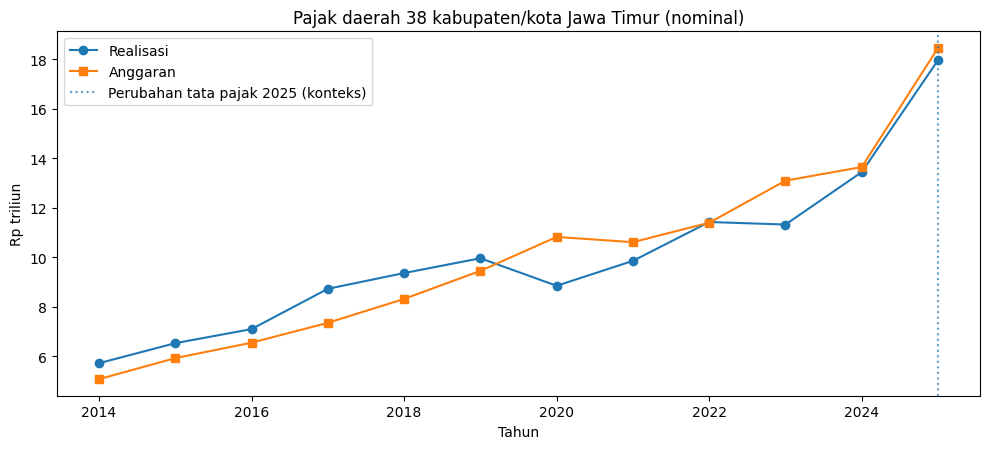

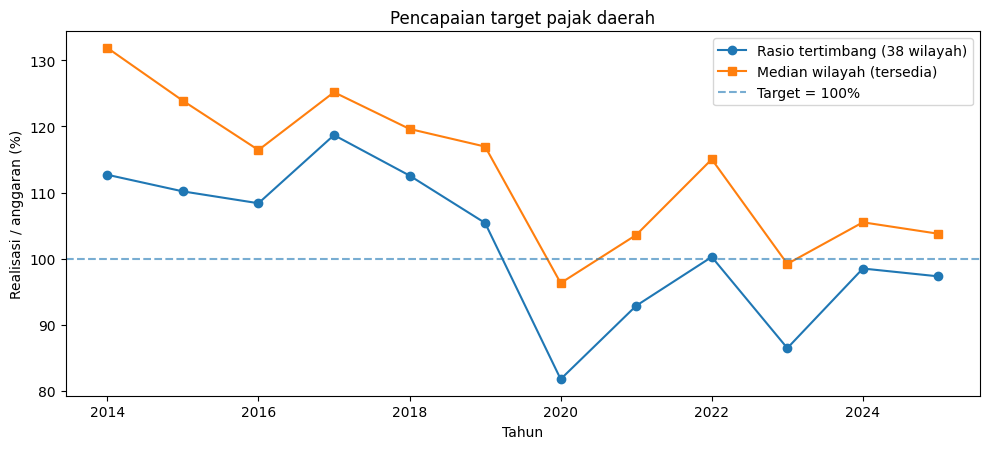

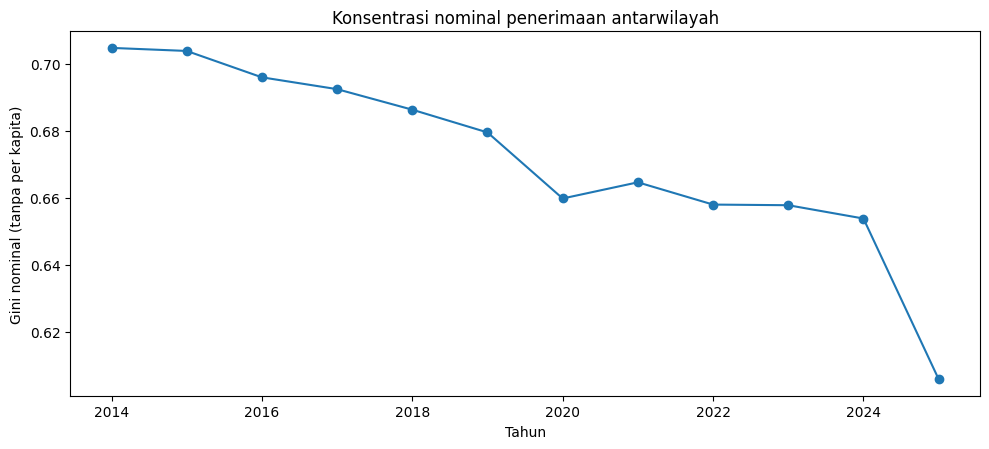

In [ ]:
fig,ax=plt.subplots(figsize=(10,4.6))
ax.plot(annual.year,annual.total_real_trillion,marker='o',label='Realisasi')
ax.plot(annual.year,annual.total_budget_trillion,marker='s',label='Anggaran')
ax.axvline(2025,ls=':',alpha=.7,label='Perubahan tata pajak 2025 (konteks)')
ax.set(title='Pajak daerah 38 kabupaten/kota Jawa Timur (nominal)',xlabel='Tahun',ylabel='Rp triliun')
ax.legend();fig.tight_layout();fig.savefig(OUT/'Gambar_1_nominal_pajak_daerah.png',dpi=180);plt.show()

fig,ax=plt.subplots(figsize=(10,4.6))
ax.plot(annual.year,annual.weighted_rate_pct,marker='o',label='Rasio tertimbang (38 wilayah)')
ax.plot(annual.year,annual.median_rate_pct,marker='s',label='Median wilayah (tersedia)')
ax.axhline(100,ls='--',alpha=.6,label='Target = 100%')
ax.set(title='Pencapaian target pajak daerah',xlabel='Tahun',ylabel='Realisasi / anggaran (%)')
ax.legend();fig.tight_layout();fig.savefig(OUT/'Gambar_2_pencapaian_target.png',dpi=180);plt.show()

fig,ax=plt.subplots(figsize=(10,4.6))
ax.plot(annual.year,annual.gini_nominal,marker='o')
ax.set(title='Konsentrasi nominal penerimaan antarwilayah',xlabel='Tahun',ylabel='Gini nominal (tanpa per kapita)')
fig.tight_layout();fig.savefig(OUT/'Gambar_3_konsentrasi_nominal.png',dpi=180);plt.show()

## 5. Regresi data panel efek tetap dua arah (analisis asosiasi)

Model utama:

\[\log(1+R_{it})=\alpha_i+\lambda_t+\beta\log(1+B_{i,t-1})+u_{it}\]

Keterangan: \(R_{it}\) realisasi pajak nominal Rp miliar, \(B_{i,t-1}\) anggaran pajak tahun sebelumnya, \(\alpha_i\) efek tetap pemerintah dan \(\lambda_t\) efek tahun. Standard error dikelompokkan per pemerintah (*cluster-robust*, 38 klaster). \(\beta\) adalah **asosiasi kondisional** pada skala log(1+x), bukan efek kausal, apalagi ukuran *tax effort*. Perhatikan keterbatasan variabel makro daerah yang tidak tersedia.

Spesifikasi sensitivitas: (i) tanpa 2025, (ii) tanpa Kota Surabaya, dan (iii) dengan lag realisasi (model FE dinamis, **rentan Nickell bias**, hanya pemeriksaan asosiasi).

In [ ]:
def run_fe(label, data, formula, terms):
    data=data.dropna(subset=['government_id','year']).copy()
    fit=smf.ols(formula,data=data).fit(
        cov_type='cluster',cov_kwds={'groups':data.government_id},use_t=False)
    bounds=fit.conf_int()
    rows=[]
    for term in terms:
        rows.append({'specification':label,'term':term,'beta':float(fit.params[term]),
          'cluster_se':float(fit.bse[term]),'p_value':float(fit.pvalues[term]),
          'ci95_low':float(bounds.loc[term,0]),'ci95_high':float(bounds.loc[term,1]),
          'n':int(fit.nobs),'n_governments':int(data.government_id.nunique()),
          'r_squared':float(fit.rsquared)})
    return rows

fe_base=panel.loc[panel.valid_observation & panel.log_budget_lag1.notna()].copy()
formula_main='log_real ~ log_budget_lag1 + C(government_id) + C(year)'
fe_rows=[]
fe_rows+=run_fe('Utama_2014_2025',fe_base,formula_main,['log_budget_lag1'])
fe_rows+=run_fe('Tanpa_2025',fe_base.loc[fe_base.year.lt(2025)],formula_main,['log_budget_lag1'])
fe_rows+=run_fe('Tanpa_Kota_Surabaya',fe_base.loc[fe_base.region.ne('Kota Surabaya')],formula_main,['log_budget_lag1'])
fe_dynamic=fe_base.dropna(subset=['log_real_lag1']).copy()
fe_rows+=run_fe('Dinamis_sensitivitas',fe_dynamic,
    'log_real ~ log_budget_lag1 + log_real_lag1 + C(government_id) + C(year)',
    ['log_budget_lag1','log_real_lag1'])
fe_results=pd.DataFrame(fe_rows)
fe_results.to_csv(OUT/'06_regresi_panel_fixed_effects.csv',index=False)
print(fe_results.round(4).to_string(index=False))
print('Interpretasi: asosiasi, bukan identifikasi kausal; pengukuran dalam log(1+Rp miliar).')

       specification            term   beta  cluster_se  p_value  ci95_low  ci95_high   n  n_governments  r_squared
     Utama_2014_2025 log_budget_lag1 0.1922      0.0733   0.0087    0.0486     0.3359 418             38     0.9938
          Tanpa_2025 log_budget_lag1 0.1316      0.0628   0.0361    0.0085     0.2548 380             38     0.9954
 Tanpa_Kota_Surabaya log_budget_lag1 0.1625      0.0702   0.0206    0.0249     0.3000 407             37     0.9920
Dinamis_sensitivitas log_budget_lag1 0.0724      0.0529   0.1708   -0.0312     0.1761 418             38     0.9951
Dinamis_sensitivitas   log_real_lag1 0.5317      0.0879   0.0000    0.3594     0.7040 418             38     0.9951
Interpretasi: asosiasi, bukan identifikasi kausal; pengukuran dalam log(1+Rp miliar).


## 6. Prediksi penerimaan satu tahun ke depan — anti-kebocoran waktu

**Waktu prediksi:** menjelang tahun `t`, setelah hasil tahun `t−1` tersedia. Fitur hanya nilai yang diketahui dari `t−1` dan sebelumnya. **Anggaran dan realisasi tahun target tidak digunakan sebagai fitur.** Target adalah `log1p(realisasi Rp miliar)`.

**Validasi bergulir:** untuk setiap tahun 2019–2023, latih pada seluruh tahun sampai `t−1`, lalu prediksi `t`. Bandingkan **Naive_lag1**, Naive tren terbatas, Ridge, Random Forest, dan HistGradientBoosting. Model dipilih **sekali** menggunakan MAE skala log pada 2019–2023.

**Uji 2024 dan 2025:** model terpilih terkunci, tetapi parameter model di-*refit* kronologis memakai informasi yang sudah tersedia: fit ≤2023 untuk meramal 2024; fit ≤2024 untuk meramal 2025. Penggunaan realisasi 2024 ketika memprediksi 2025 **sah** karena diketahui pada origin 2025, tetapi realisasi 2025 tidak pernah dipakai untuk menyesuaikan prediksi 2025. Dua tahun uji ini tidak mewakili banyak siklus ekonomi.

In [ ]:
NUM_FEATURES=['log_real_lag1','log_real_lag2','log_budget_lag1','log_budget_lag2',
    'rate_pct_lag1','rate_pct_lag2','log_real_growth_lag','log_budget_growth_lag','calendar_trend']
CAT_FEATURES=['government_id','region_type']
FEATURES=NUM_FEATURES+CAT_FEATURES
MODEL_NAMES=['Naive_lag1','Naive_tren','Ridge','RandomForest','HistGradientBoosting']
model_panel=panel.loc[panel.forecast_eligible & panel.log_real_lag2.notna() & panel.year.between(2016,2025)].copy()
assert all(('lag' in x or x=='calendar_trend') for x in NUM_FEATURES)
assert all(c not in FEATURES for c in ['log_real','real_bil','budget_bil','rate_pct','growth_nominal_pct'])
assert model_panel[NUM_FEATURES].notna().all().all(), 'Lag prediksi belum lengkap'
assert model_panel.year.min()==2016

def preprocessing():
    num=Pipeline([('imputer',SimpleImputer(strategy='median',add_indicator=True)),
                  ('scale',StandardScaler())])
    # Dukungan sklearn lawas bila diperlukan (Colab versi tertentu).
    try:
        encoder=OneHotEncoder(handle_unknown='ignore',sparse_output=False)
    except TypeError:
        encoder=OneHotEncoder(handle_unknown='ignore',sparse=False)
    return ColumnTransformer([('num',num,NUM_FEATURES),('cat',encoder,CAT_FEATURES)],
                              sparse_threshold=0)

def make_model(name):
    if name=='Ridge':
        reg=Ridge(alpha=12.0)
    elif name=='RandomForest':
        reg=RandomForestRegressor(n_estimators=180,min_samples_leaf=3,
                                  max_depth=9,max_features=0.9,n_jobs=-1,random_state=SEED)
    elif name=='HistGradientBoosting':
        reg=HistGradientBoostingRegressor(max_iter=140,max_leaf_nodes=12,
                  min_samples_leaf=12,learning_rate=0.05,l2_regularization=1.0,
                  random_state=SEED)
    else:
        raise ValueError(name)
    return Pipeline([('preprocess',preprocessing()),('regressor',reg)])

def predict_one_year(name,year):
    train=model_panel.loc[model_panel.year.lt(year)].copy()
    test=model_panel.loc[model_panel.year.eq(year)].copy()
    if not len(train) or not len(test):
        raise ValueError(f'Tidak tersedia data train/test valid untuk tahun {year}.')
    if train.year.max()!=year-1:
        raise AssertionError(f'Leakage/urutan waktu tidak valid untuk tahun {year}')
    if name=='Naive_lag1':
        predicted=test.log_real_lag1.to_numpy(dtype=float)
    elif name=='Naive_tren':
        trend=(test.log_real_lag1-test.log_real_lag2).fillna(0).clip(-.35,.35)
        predicted=(test.log_real_lag1+trend).to_numpy(dtype=float)
    else:
        model=make_model(name)
        model.fit(train[FEATURES],train.log_real)
        predicted=model.predict(test[FEATURES])
    out=test[['government_id','region','region_type','year','real_bil','log_real',
              'rate_pct','budget_bil']].copy()
    out['train_end_year']=int(train.year.max())
    out['model']=name
    out['pred_log']=np.clip(np.asarray(predicted,dtype=float),0,30)
    out['pred_bil']=np.expm1(out.pred_log)
    out['abs_error_log']=np.abs(out.log_real-out.pred_log)
    out['abs_error_bil']=np.abs(out.real_bil-out.pred_bil)
    out['error_bil']=out.pred_bil-out.real_bil
    return out

def scores(group):
    act=group.real_bil.to_numpy(dtype=float)
    pred=group.pred_bil.to_numpy(dtype=float)
    return pd.Series({
       'n':len(group),
       'MAE_log':group.abs_error_log.mean(),
       'MAE_Rp_miliar':group.abs_error_bil.mean(),
       'RMSE_Rp_miliar':np.sqrt(np.mean((act-pred)**2)),
       'WAPE_pct':100*np.sum(np.abs(act-pred))/np.sum(act) if np.sum(act)>0 else np.nan,
       'bias_pred_minus_actual_Rp_miliar':np.mean(pred-act)
    })
print('Fitur prediksi:',FEATURES)
print('Model pembanding:',MODEL_NAMES)

Fitur prediksi: ['log_real_lag1', 'log_real_lag2', 'log_budget_lag1', 'log_budget_lag2', 'rate_pct_lag1', 'rate_pct_lag2', 'log_real_growth_lag', 'log_budget_growth_lag', 'calendar_trend', 'government_id', 'region_type']
Model pembanding: ['Naive_lag1', 'Naive_tren', 'Ridge', 'RandomForest', 'HistGradientBoosting']


In [ ]:
val_pred=pd.concat([predict_one_year(model,year)
    for year in VALIDATION_YEARS for model in MODEL_NAMES],ignore_index=True)
val_summary=(val_pred.groupby('model').apply(scores,include_groups=False)
    .sort_values(['MAE_log','MAE_Rp_miliar']).reset_index())
val_summary['ranking_validasi']=np.arange(1,len(val_summary)+1)
SELECTED_MODEL=str(val_summary.loc[0,'model'])
val_pred.to_csv(OUT/'07_prediksi_validasi_2019_2023.csv',index=False)
val_summary.to_csv(OUT/'08_skor_validasi_dan_pemilihan_model.csv',index=False)
print(val_summary.round(4).to_string(index=False))
print('MODEL DIPILIH dari validasi 2019–2023 (tanpa melihat test):',SELECTED_MODEL)
assert val_pred.year.max()==2023
assert val_pred.groupby(['model','year']).size().eq(38).all()
assert val_pred.train_end_year.lt(val_pred.year).all()

               model     n  MAE_log  MAE_Rp_miliar  RMSE_Rp_miliar  WAPE_pct  bias_pred_minus_actual_Rp_miliar  ranking_validasi
          Naive_lag1 190.0   0.1027        26.5124         78.5188    9.7963                          -10.3164                 1
               Ridge 190.0   0.1182        31.1686         95.0571   11.5167                           -6.3201                 2
        RandomForest 190.0   0.1299        54.7720        211.8573   20.2381                          -12.5682                 3
          Naive_tren 190.0   0.1421        38.9319        117.8993   14.3853                            8.2744                 4
HistGradientBoosting 190.0   0.1787        94.3642        344.8598   34.8673                          -11.2115                 5
MODEL DIPILIH dari validasi 2019–2023 (tanpa melihat test): Naive_lag1


## 7. Uji 2024–2025: evaluasi **setelah** pemilihan model

Setiap tahun uji adalah **prediksi satu langkah** dengan model dan data pelatihan sebelumnya. Seluruh kandidat tetap dilaporkan untuk transparansi, tetapi keputusan metode telah dibuat pada 2019–2023. Uji 2025 tidak boleh dianggap bukti kausal apa pun tentang opsen.

Hasil test 2024–25 (model tidak dipilih dari test):
 year                model    n  MAE_log  MAE_Rp_miliar  WAPE_pct  selected_on_validation
 2024 HistGradientBoosting 38.0    0.142         88.464    25.006                   False
 2024           Naive_lag1 38.0    0.181         55.757    15.760                    True
 2024           Naive_tren 38.0    0.194         58.198    16.450                   False
 2024         RandomForest 38.0    0.094         51.877    14.664                   False
 2024                Ridge 38.0    0.166         59.330    16.770                   False
 2025 HistGradientBoosting 38.0    0.368        172.778    36.544                   False
 2025           Naive_lag1 38.0    0.419        119.022    25.174                    True
 2025           Naive_tren 38.0    0.263         65.866    13.931                   False
 2025         RandomForest 38.0    0.357        131.192    27.748                   False
 2025                Ridge 38.0    0.379        

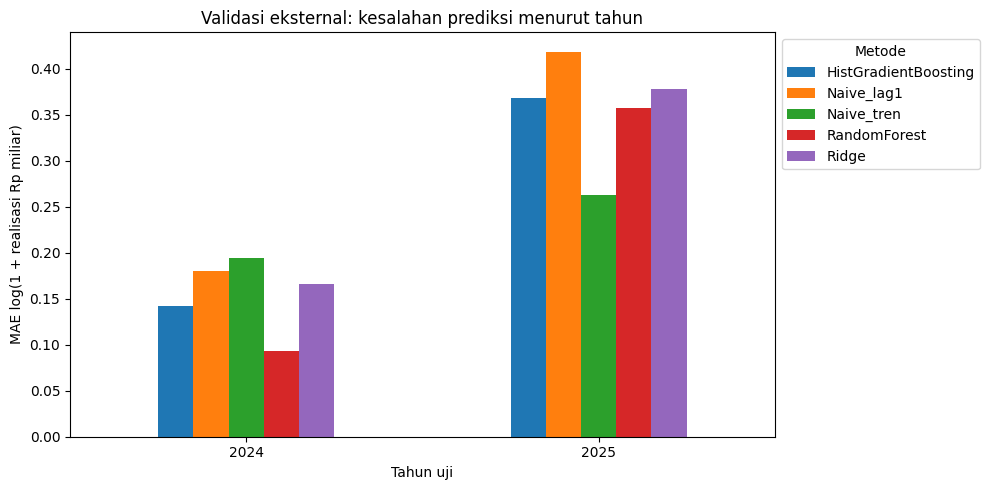

In [ ]:
test_pred=pd.concat([predict_one_year(model,year)
    for year in TEST_YEARS for model in MODEL_NAMES],ignore_index=True)
test_score=(test_pred.groupby(['year','model']).apply(scores,include_groups=False).reset_index())
test_score['selected_on_validation']=test_score.model.eq(SELECTED_MODEL)
test_score.to_csv(OUT/'10_skor_test_per_tahun.csv',index=False)
test_pred.to_csv(OUT/'09_prediksi_test_2024_2025.csv',index=False)
pooled=(test_pred.groupby('model').apply(scores,include_groups=False)
    .reset_index().sort_values('MAE_log'))
pooled['selected_on_validation']=pooled.model.eq(SELECTED_MODEL)
pooled.to_csv(OUT/'11_skor_test_gabungan.csv',index=False)
print('Hasil test 2024–25 (model tidak dipilih dari test):')
print(test_score[['year','model','n','MAE_log','MAE_Rp_miliar','WAPE_pct',
    'selected_on_validation']].round(3).to_string(index=False))
print('Model terpilih:',SELECTED_MODEL)
assert test_pred.groupby(['model','year']).size().eq(38).all()
assert test_pred.loc[test_pred.year.eq(2024),'train_end_year'].eq(2023).all()
assert test_pred.loc[test_pred.year.eq(2025),'train_end_year'].eq(2024).all()

fig,ax=plt.subplots(figsize=(10,5))
pt=test_score.pivot(index='year',columns='model',values='MAE_log')
pt.plot(kind='bar',ax=ax,rot=0)
ax.set(title='Validasi eksternal: kesalahan prediksi menurut tahun',xlabel='Tahun uji',
       ylabel='MAE log(1 + realisasi Rp miliar)')
ax.legend(loc='upper left',bbox_to_anchor=(1,1),title='Metode')
fig.tight_layout();fig.savefig(OUT/'Gambar_4_evaluasi_prediksi.png',dpi=180,bbox_inches='tight');plt.show()

## 8. Pemeriksaan ketidakpastian dan komparasi berpasangan

Interval **indikatif 80%** dibuat dari kuantil ke-80 kesalahan absolut `log` pada prediksi validasi bergulir 2019–2023 **untuk model terpilih**. Interval ini tidak menjamin cakupan 80%, terutama saat ada perubahan rezim fiskal atau dependensi serial antardaerah. Bootstrap mengacak **klaster pemerintah** untuk beda rata-rata kesalahan model terpilih vs naif pada dua tahun test. Jika model terpilih adalah Naive_lag1, perbedaan ini **secara matematis nol**, sehingga bootstrap tidak menunjukkan keunggulan model baru. Interval bersifat indikatif, bukan alat keputusan operasional.

In [ ]:
chosen=test_pred.loc[test_pred.model.eq(SELECTED_MODEL)].copy()
calib=val_pred.loc[val_pred.model.eq(SELECTED_MODEL),'abs_error_log'].dropna().to_numpy()
q80=float(np.quantile(calib,.80))
chosen['pi80_lower_bil']=np.expm1(np.maximum(0,chosen.pred_log-q80))
chosen['pi80_upper_bil']=np.expm1(chosen.pred_log+q80)
chosen['pi80_covered']=(chosen.real_bil>=chosen.pi80_lower_bil)&(chosen.real_bil<=chosen.pi80_upper_bil)
chosen['pi80_width_bil']=chosen.pi80_upper_bil-chosen.pi80_lower_bil
pi_stats=(chosen.groupby('year',as_index=False).agg(n=('pi80_covered','size'),
    empirical_coverage=('pi80_covered','mean'),mean_width_bil=('pi80_width_bil','mean')))
chosen.to_csv(OUT/'12_interval_indikatif_dan_prediksi_terpilih.csv',index=False)
pi_stats.to_csv(OUT/'13_kinerja_interval_indikatif.csv',index=False)
print('Kuantil kesalahan validasi yang dipakai untuk interval:',round(q80,4))
print(pi_stats.round(3).to_string(index=False))

ref=(test_pred.loc[test_pred.model.eq('Naive_lag1'),['government_id','year','abs_error_log']]
     .rename(columns={'abs_error_log':'error_naive'}))
paired=chosen[['government_id','year','abs_error_log']].merge(ref,on=['government_id','year'],validate='one_to_one')
paired['difference_selected_minus_naive']=paired.abs_error_log-paired.error_naive
cluster_diff=paired.groupby('government_id').difference_selected_minus_naive.mean().to_numpy()
rng=np.random.default_rng(SEED)
boots=np.mean(rng.choice(cluster_diff,size=(4000,len(cluster_diff)),replace=True),axis=1)
lo,hi=np.quantile(boots,[0.025,0.975])
comparison=pd.DataFrame([{'selected_model':SELECTED_MODEL,
  'mean_difference_MAE_log':float(cluster_diff.mean()),
  'cluster_bootstrap_CI95_low':float(lo),'cluster_bootstrap_CI95_high':float(hi),
  'n_clusters':len(cluster_diff),'years':'2024–2025',
  'note':'conditional on 2 observed test years; no causal interpretation'}])
paired.to_csv(OUT/'14_selisih_per_pemerintah_tahun.csv',index=False)
comparison.to_csv(OUT/'15_bootstrap_klaster_selisih_mae.csv',index=False)
print(comparison.round(5).to_string(index=False))

Kuantil kesalahan validasi yang dipakai untuk interval: 0.1611
 year  n  empirical_coverage  mean_width_bil
 2024 38               0.395          96.732
 2025 38               0.079         114.770
selected_model  mean_difference_MAE_log  cluster_bootstrap_CI95_low  cluster_bootstrap_CI95_high  n_clusters     years                                                           note
    Naive_lag1                      0.0                         0.0                          0.0          38 2024–2025 conditional on 2 observed test years; no causal interpretation


## 9. Robustness: Kabupaten/Kota, 2025, dan validitas klaim ekonomi

Analisis per Kota/Kabupaten dan perubahan agregat 2025 adalah **deskriptif**. Mulai 2025 terjadi perubahan kerangka pajak daerah (opsen), sehingga pertumbuhan nominal 2025 tidak boleh otomatis dianggap kenaikan efisiensi, basis pajak, atau efek kausal kebijakan. Untuk menguji reformasi, diperlukan rincian komponen pajak dan rancangan identifikasi terpisah.

SUBGRUP:
  year region_type    n  MAE_log  MAE_Rp_miliar  RMSE_Rp_miliar  WAPE_pct  bias_pred_minus_actual_Rp_miliar
 2024   Kabupaten 29.0    0.176         40.939          66.071    16.520                           -40.939
 2024        Kota  9.0    0.196        103.501         222.777    14.888                          -103.501
 2025   Kabupaten 29.0    0.459         99.998         119.044    28.750                           -99.998
 2025        Kota  9.0    0.290        180.320         401.672    20.596                          -180.320
PERIODE PENTING:
  year  n_valid  total_budget_trillion  total_real_trillion  weighted_rate_pct  total_real_yoy_pct  gini_nominal
 2019       38                  9.452                9.962            105.400               6.382         0.680
 2020       38                 10.823                8.851             81.773             -11.158         0.660
 2023       38                 13.097               11.325             86.466              -0.891    

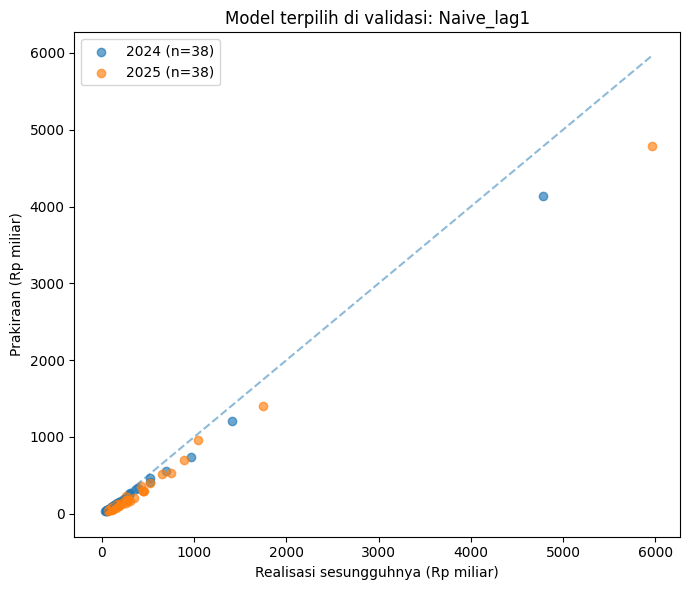

In [ ]:
subgroup=(chosen.groupby(['year','region_type']).apply(scores,include_groups=False).reset_index())
subgroup.to_csv(OUT/'16_skor_terpilih_per_jenis_daerah.csv',index=False)
recent=annual.loc[annual.year.isin([2019,2020,2023,2024,2025]),
    ['year','n_valid','total_budget_trillion','total_real_trillion',
     'weighted_rate_pct','total_real_yoy_pct','gini_nominal']].copy()
recent.to_csv(OUT/'17_statistik_periode_penting.csv',index=False)
print('SUBGRUP:\n',subgroup.round(3).to_string(index=False))
print('PERIODE PENTING:\n',recent.round(3).to_string(index=False))

fig,ax=plt.subplots(figsize=(7,6))
for year,sub in chosen.groupby('year'):
    ax.scatter(sub.real_bil,sub.pred_bil,alpha=.65,label=f'{year} (n={len(sub)})')
upper=max(chosen.real_bil.max(),chosen.pred_bil.max())
ax.plot([0,upper],[0,upper],ls='--',alpha=.5)
ax.set(xlabel='Realisasi sesungguhnya (Rp miliar)',ylabel='Prakiraan (Rp miliar)',
       title=f'Model terpilih di validasi: {SELECTED_MODEL}')
ax.legend();fig.tight_layout();fig.savefig(OUT/'Gambar_5_aktual_vs_prediksi.png',dpi=180);plt.show()

## 10. Perbandingan antar-kabupaten dan kota di Jawa Timur

Perhitungan meliputi kontribusi nominal kelompok **29 kabupaten vs 9 kota**, penerimaan rata-rata per pemerintah, tingkat pencapaian target, peringkat seluruh 38 pemerintah pada 2025, dan perubahan 2024–2025. Peringkat nominal tidak mengukur kapasitas atau efisiensi pemungutan tanpa penduduk, PDRB, dan basis pajak.

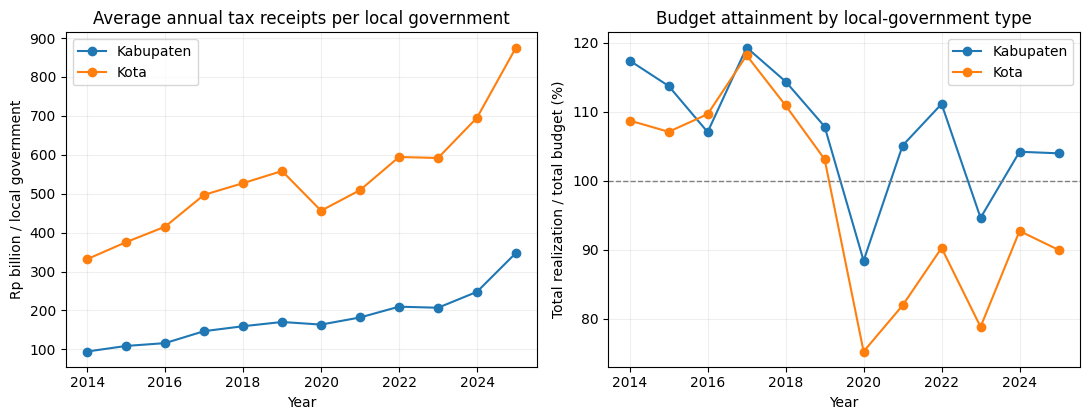

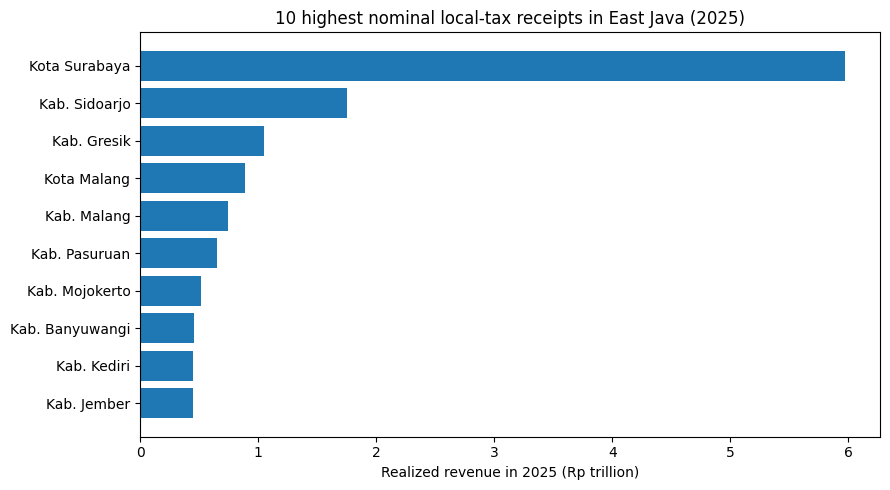

Surabaya composition sensitivity:                      group  n  total_real_bil  weighted_rate_pct
                    9 Kota  9         7879.56             89.971
8 Kota, excluding Surabaya  8         1910.60            103.926
2025 group comparison:
 year region_type  n  total_real_bil  total_budget_bil  median_rate_pct  mean_rate_pct  mean_real_bil  median_real_bil  n_below_target  weighted_rate_pct  share_all_jatim_pct  pct_below_target
 2025   Kabupaten 29        10086.71           9702.54          103.719        105.576        347.818           262.34               5            103.959               56.142            17.241
 2025        Kota  9         7879.56           8757.88          105.019        101.280        875.507           164.89               3             89.971               43.858            33.333
2025 top 10 regions:
         region  real_bil  province_share_pct  rate_pct
  Kota Surabaya   5968.96              33.223    86.263
  Kab. Sidoarjo   1750.89           

In [ ]:
# Perbandingan antardaerah dan antara kelompok kabupaten vs kota.
# Seluruh angka bersifat nominal (tidak dibagi penduduk dan tidak disesuaikan inflasi).
yearly_sub=(panel.groupby(['year','region_type'],as_index=False)
    .agg(n=('government_id','nunique'),total_real_bil=('real_bil','sum'),
         total_budget_bil=('budget_bil','sum'),median_rate_pct=('rate_pct','median'),
         mean_rate_pct=('rate_pct','mean'),mean_real_bil=('real_bil','mean'),
         median_real_bil=('real_bil','median'),
         n_below_target=('rate_pct',lambda s:int((s<100).sum()))))
yearly_sub['weighted_rate_pct']=100*yearly_sub.total_real_bil/yearly_sub.total_budget_bil
yearly_sub['share_all_jatim_pct']=yearly_sub.groupby('year').total_real_bil.transform(lambda x:100*x/x.sum())
yearly_sub['pct_below_target']=100*yearly_sub.n_below_target/yearly_sub.n
yearly_sub=yearly_sub.sort_values(['year','region_type'])
yearly_sub.to_csv(OUT/'20_perbandingan_kabupaten_kota_tahunan.csv',index=False)
regional=panel.loc[panel.year.eq(2025),['government_id','region','region_type','real_bil','budget_bil','rate_pct']].copy()
regional['province_share_pct']=100*regional.real_bil/regional.real_bil.sum()
regional['rank_revenue_2025']=regional.real_bil.rank(ascending=False,method='first').astype(int)
regional=regional.sort_values('real_bil',ascending=False)
regional.to_csv(OUT/'21_peringkat_38_wilayah_2025.csv',index=False)
a=panel.loc[panel.year.eq(2024),['government_id','real_bil','rate_pct']].rename(columns={'real_bil':'real_2024_bil','rate_pct':'rate_2024_pct'})
b=panel.loc[panel.year.eq(2025),['government_id','region','region_type','real_bil','rate_pct']].rename(columns={'real_bil':'real_2025_bil','rate_pct':'rate_2025_pct'})
changes=b.merge(a,on='government_id',validate='one_to_one')
changes['growth_2025_pct']=100*(changes.real_2025_bil/changes.real_2024_bil-1)
changes['rate_change_pp']=changes.rate_2025_pct-changes.rate_2024_pct
changes.to_csv(OUT/'22_pertumbuhan_per_wilayah_2025.csv',index=False)
# Group shares and same-scale per-jurisdiction comparisons
fig,axs=plt.subplots(1,2,figsize=(11,4.3))
for category in ['Kabupaten','Kota']:
    s=yearly_sub[yearly_sub.region_type.eq(category)]
    axs[0].plot(s.year,s.mean_real_bil,marker='o',label=category)
    axs[1].plot(s.year,s.weighted_rate_pct,marker='o',label=category)
axs[0].set(title='Average annual tax receipts per local government',xlabel='Year',ylabel='Rp billion / local government')
axs[1].set(title='Budget attainment by local-government type',xlabel='Year',ylabel='Total realization / total budget (%)')
axs[1].axhline(100,ls='--',c='gray',lw=1)
for a in axs: a.grid(alpha=.2);a.legend()
fig.tight_layout();fig.savefig(OUT/'Gambar_6_perbandingan_kabupaten_kota.png',dpi=190);plt.show()
fig,ax=plt.subplots(figsize=(9,5.0))
top=regional.head(10).iloc[::-1]
ax.barh(top.region,top.real_bil/1000)
ax.set(xlabel='Realized revenue in 2025 (Rp trillion)',title='10 highest nominal local-tax receipts in East Java (2025)')
fig.tight_layout();fig.savefig(OUT/'Gambar_7_top10_wilayah_2025.png',dpi=190,bbox_inches='tight');plt.show()
# Komposisi kota sangat dipengaruhi Surabaya; bandingkan juga tanpa Surabaya.
city2025=regional.loc[regional.region_type.eq('Kota')]
city_ex=city2025.loc[~city2025.region.eq('Kota Surabaya')]
city_sensitivity=pd.DataFrame([
 {'group':'9 Kota','n':len(city2025),'total_real_bil':city2025.real_bil.sum(),
  'weighted_rate_pct':100*city2025.real_bil.sum()/city2025.budget_bil.sum()},
 {'group':'8 Kota, excluding Surabaya','n':len(city_ex),'total_real_bil':city_ex.real_bil.sum(),
  'weighted_rate_pct':100*city_ex.real_bil.sum()/city_ex.budget_bil.sum()}
])
city_sensitivity.to_csv(OUT/'23_sensitivitas_kota_tanpa_surabaya.csv',index=False)
print('Surabaya composition sensitivity:',city_sensitivity.round(3).to_string(index=False))
print('2025 group comparison:')
print(yearly_sub.loc[yearly_sub.year.eq(2025)].round(3).to_string(index=False))
print('2025 top 10 regions:')
print(regional[['region','real_bil','province_share_pct','rate_pct']].head(10).round(3).to_string(index=False))
print('2025 growth median across localities:',round(changes.growth_2025_pct.median(),3))

## 11. Manifest replikasi dan batas pelaporan jurnal

Sel terakhir membuat `19_RINGKASAN_HASIL_UNTUK_JURNAL.md` otomatis dari angka hasil eksekusi, bukan dari notebook APBD lama. Untuk publikasi, laporkan: sampel dan *missingness*, definisi satuan, 2011–2013 serta 2026 dikeluarkan, nilai nominal, spesifikasi FE, kesalahan validasi dan uji per tahun, hasil dibandingkan Naive, dan kelemahan identifikasi kausal. **Jangan menjanjikan diterima SINTA 3**; perlu pemeriksaan sumber, diskusi literatur ekonomi, dan kesesuaian ketentuan jurnal sasaran.

In [ ]:
main_fe=fe_results.loc[fe_results.specification.eq('Utama_2014_2025')].iloc[0]
selected_scores=test_score.loc[test_score.model.eq(SELECTED_MODEL)].sort_values('year')
y24=selected_scores.loc[selected_scores.year.eq(2024)].iloc[0]
y25=selected_scores.loc[selected_scores.year.eq(2025)].iloc[0]
growth25=float(annual.loc[annual.year.eq(2025),'total_real_yoy_pct'].iloc[0])
manifest={
 'project':'Analisis Ekonomi Pajak Daerah Jatim 38 Kabupaten/Kota 2014–2025',
 'csv_filename':FILENAME,'csv_sha256':DATA_SHA256,
 'source_years':[int(raw.tahun.min()),int(raw.tahun.max())],
 'analysis_years':[2014,2025],
 'analysis_rows':int(len(panel)),
 'valid_rows':int(panel.valid_observation.sum()),
 'regions':int(panel.government_id.nunique()),
 'analysis_missing_rows':0,
 'excluded_year_2026':True,
 'forecast_validation_years':VALIDATION_YEARS,
 'forecast_test_years':TEST_YEARS,
 'forecast_strategy':'expanding one-step-ahead; 2024 train <=2023, 2025 train <=2024',
 'selection_metric':'MAE_log','model_selected_on_validation':SELECTED_MODEL,
 'features':FEATURES,'seed':SEED,'python':platform.python_version(),
 'pandas':pd.__version__,
 'limitations':['nominal rupiah, no regional inflation or GDP deflator',
                'no per-capita or tax-base denominator',
                'one aggregate annual local-tax account; no monthly early warning',
                '2025 policy and classification changes not causally identified',
                'two test years; interval calibration indicative only']}
(OUT/'18_manifest_replikasi.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
summary=f"""# Ringkasan hasil yang boleh dilaporkan pada jurnal ekonomi\n\n**Dataset asli:** {FILENAME}, SHA-256 `{DATA_SHA256}`.\n\n**Cakupan:** {len(panel)} baris tahun-daerah (2014–2025), {panel.valid_observation.sum()} valid, 38 kabupaten/kota. Tidak ada nilai sumber yang hilang dalam 2014–2025; 2011–2013 dan 2026 tidak digunakan.\n\n**Topik ekonomi:** rasio pencapaian anggaran, penerimaan nominal, konsentrasi antarwilayah, asosiasi FE, dan prakiraan penerimaan setahun ke depan.\n\n**FE utama:** beta log anggaran tahun sebelumnya = {main_fe.beta:.4f}; SE klaster daerah = {main_fe.cluster_se:.4f}; CI 95% [{main_fe.ci95_low:.4f}, {main_fe.ci95_high:.4f}]; n={main_fe.n}. BUKAN efek kausal.\n\n**Model prakiraan terpilih pada validasi {VALIDATION_YEARS[0]}–{VALIDATION_YEARS[-1]}:** {SELECTED_MODEL}. Metrik seleksi adalah MAE-log.\n\n**Uji 2024:** MAE-log {y24.MAE_log:.4f}; WAPE {y24.WAPE_pct:.2f}%; MAE nominal {y24.MAE_Rp_miliar:.2f} Rp miliar. Fit hanya sampai 2023.\n\n**Uji 2025:** MAE-log {y25.MAE_log:.4f}; WAPE {y25.WAPE_pct:.2f}%; MAE nominal {y25.MAE_Rp_miliar:.2f} Rp miliar. Fit hanya sampai 2024.\n\n**Pertumbuhan nominal agregat 2025 dibanding 2024:** {growth25:.2f}%, deskriptif, tanpa klaim sebab-akibat.\n\n**Ketidakpastian:** interval empiris indikatif 80% dikalibrasi dari prediksi validasi 2019–2023; ukur cakupan aktual pada file `13_kinerja_interval_indikatif.csv`.\n\n**Peringatan metodologis:** tidak ada PDRB, penduduk, inflasi, rincian opsen maupun kapasitas pemungutan. Data tidak mendukung klaim tax effort, *dampak kebijakan*, maupun prediksi APBD bulanan. Agregat 2013 dan perbandingan agregat pertumbuhan yoy dimulai dari 2015.\n"""
(OUT/'19_RINGKASAN_HASIL_UNTUK_JURNAL.md').write_text(summary,encoding='utf-8')
print('\nSELESAI — seluruh output berasal dari CSV yang ditentukan.\n')
print('Model terpilih:',SELECTED_MODEL)
print('Folder:',OUT)
print('Berkas hasil:',len(list(OUT.iterdir())))


SELESAI — seluruh output berasal dari CSV yang ditentukan.

Model terpilih: Naive_lag1
Folder: /mnt/data/ULANG_JURNAL_EKONOMI_JATIM_2014_2025/hasil_jurnal_ekonomi_pajak_2014_2025
Berkas hasil: 30
